# Bagging: many bootstrap-trained trees

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/tree-based/05-bagging.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

A decision tree can be very sensitive to the particular observations it is trained on, i.e., overfit (high-variance). **Bagging (bootstrap aggregating)**, which is one type of ensemble methods, can help to reduce the variance. Specifically, we fit many trees on bootstrap versions of one training dataset, then average their predictions.

We will use the gas-turbine positive-label task to see each part of that process.

## What you will do

1. Construct bootstrap datasets mechanically: sample the training rows with replacement.
2. Fit one deep tree on this dataset and evaluate it on held-out observations.
3. Repeat steps 1 and 2 to obtain multiple models (trees), then make a prediction by averaging each base model's prediction.
4. Compare individual bootstrap trees and the bagged ensemble on the same test set.

In [1]:
from pathlib import Path
from typing import Any
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
bagging_color = sns.color_palette("deep")[1]

## 1. Set up the same classification task

As before, each row in the dataset is one gas-turbine operating observation. We use nine measured operating features to predict the binary `high_co` label. `CO` itself is excluded because it defines that label.

We use a fixed 70/30 stratified train/test split. Every model in this notebook is evaluated on this same held-out test set.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/changyaochen/MECE4520/master/"
    "site/data/gas-turbine-course.csv"
)
data_candidates = [
    Path("../data/gas-turbine-course.csv"),
    Path("site/data/gas-turbine-course.csv"),
    Path("gas-turbine-course.csv"),
]
data_path = next((path for path in data_candidates if path.exists()), data_candidates[-1])

# In Google Colab, retrieve the course dataset only when it is not already present.
if not data_path.exists():
    urlretrieve(url=DATA_URL, filename=data_path)

FEATURES = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
TARGET = "high_co"
RANDOM_STATE = 4520
MAX_DEPTH = 5
FIXED_TEST_POSITION = 4520

data = pd.read_csv(filepath_or_buffer=data_path)
model_data = data[FEATURES + [TARGET]].dropna().copy()

X_train, X_test, y_train, y_test = train_test_split(
    model_data[FEATURES],
    model_data[TARGET],
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=model_data[TARGET],
)

split_summary = pd.DataFrame(
    {
        "observations": [len(X_train), len(X_test)],
        "positive-label fraction": [y_train.mean(), y_test.mean()],
    },
    index=["Training set", "Test set"],
)
split_summary.style.format({"positive-label fraction": "{:.1%}"})

,observations,positive-label fraction
Training set,24778,38.8%
Test set,10620,38.8%


## 2. Make one bootstrap dataset

A bootstrap dataset has exactly $n$ rows when the original training set has $n$ rows. We draw the rows **with replacement**, so a source row can be used zero, one, or several times. The total number of draws remains $n$.

In [3]:
rng = np.random.default_rng(seed=RANDOM_STATE)
bootstrap_positions = rng.integers(low=0, high=len(X_train), size=len(X_train))
bootstrap_counts = np.bincount(bootstrap_positions, minlength=len(X_train))
X_bootstrap = X_train.iloc[bootstrap_positions].reset_index(drop=True)
y_bootstrap = y_train.iloc[bootstrap_positions].reset_index(drop=True)

bootstrap_overview = pd.DataFrame(
    {
        "number of appearances": [0, 1, 2, 3, "4+"],
        "training rows": [
            np.sum(bootstrap_counts == 0),
            np.sum(bootstrap_counts == 1),
            np.sum(bootstrap_counts == 2),
            np.sum(bootstrap_counts == 3),
            np.sum(bootstrap_counts >= 4),
        ],
    }
)
print(f"Bootstrap draws: {len(bootstrap_positions):,}")
print(f"Distinct source rows represented: {np.sum(bootstrap_counts > 0):,}")
bootstrap_overview

Bootstrap draws: 24,778
Distinct source rows represented: 15,605


,number of appearances,training rows
0,0,9173
1,1,9019
2,2,4565
3,3,1556
4,4+,465


## 3. Fit one tree to that dataset

We fit one depth-5 decision tree to the bootstrap dataset. ROC AUC measures how well its probability scores rank positive and negative observations in the held-out test set.

In [4]:
def auc_scores(
    *,
    model: Any,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    y_test: pd.Series,
) -> dict[str, float]:
    """Compute training and held-out ROC AUC for a fitted classifier.

    Args:
        model: A fitted classifier that provides ``predict_proba``.
        X_train: Features used to fit the model.
        y_train: Training labels.
        X_test: Held-out feature values.
        y_test: Held-out labels.

    Returns:
        Training and held-out ROC AUC values.
    """
    training_probability = model.predict_proba(X_train)[:, 1]
    test_probability = model.predict_proba(X_test)[:, 1]
    return {
        "training AUC": roc_auc_score(y_train, training_probability),
        "test AUC": roc_auc_score(y_test, test_probability),
    }


one_tree = DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=RANDOM_STATE)
one_tree.fit(X=X_bootstrap, y=y_bootstrap)
one_tree_scores = auc_scores(
    model=one_tree,
    X_train=X_bootstrap,
    y_train=y_bootstrap,
    X_test=X_test,
    y_test=y_test,
)
pd.DataFrame([one_tree_scores], index=[f"One depth-{MAX_DEPTH} bootstrap tree"]).round(3)

,training AUC,test AUC
One depth-5 bootstrap tree,0.897,0.893


## 4. Repeat the process and pool the predictions

Bagging repeats steps 2 and 3 $B$ times. Each tree is fitted independently on one bootstrap dataset. For a new feature vector $\mathbf{x}$, the ensemble averages the trees' positive-label probabilities:

$$
\hat{p}_{\mathrm{bag}}(\mathbf{x}) = \frac{1}{B} \sum_{b=1}^{B} \hat{p}_{b}(\mathbf{x}).
$$

In [5]:
N_TREES = 200

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=MAX_DEPTH),
    n_estimators=N_TREES,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
bagging.fit(X=X_train, y=y_train)

bagging_scores = auc_scores(
    model=bagging,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
)
pd.DataFrame(
    [one_tree_scores, bagging_scores],
    index=[f"One depth-{MAX_DEPTH} bootstrap tree", f"Bagging ({N_TREES} trees)"],
).round(3)

,training AUC,test AUC
One depth-5 bootstrap tree,0.897,0.893
Bagging (200 trees),0.911,0.908


## 5. Pool the tree predictions for one held-out observation

For one fixed held-out observation, each fitted tree produces a probability. Bagging uses their running average as its pooled prediction.

Fixed observation label: 1
Pooled probability after 200 trees: 0.838


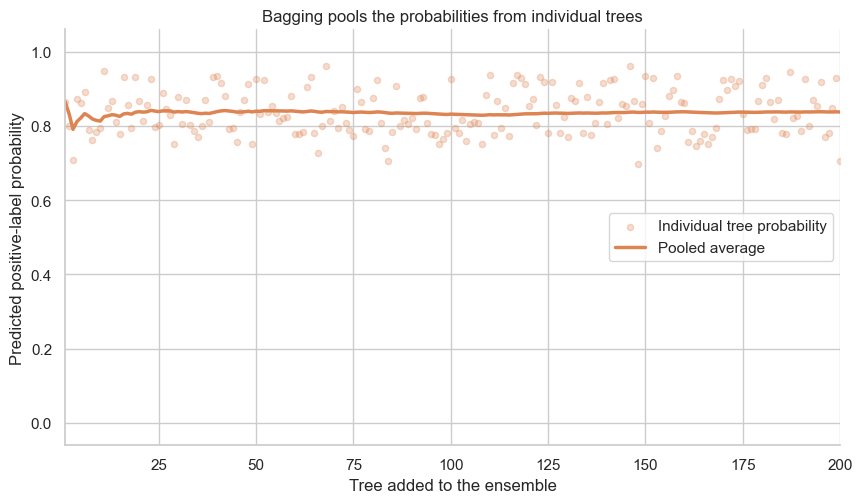

In [6]:
def individual_tree_probabilities(*, model: Any, X: pd.DataFrame) -> np.ndarray:
    """Collect held-out positive-label probabilities from every bagged tree.

    Args:
        model: A fitted bagging classifier.
        X: Feature values to score.

    Returns:
        An array with one probability column per fitted tree.
    """
    X_values = X.to_numpy()
    return np.column_stack(
        [tree.predict_proba(X_values)[:, 1] for tree in model.estimators_]
    )


bagging_tree_probabilities = individual_tree_probabilities(model=bagging, X=X_test)
tree_counts = np.arange(1, N_TREES + 1)
example_label = int(y_test.iloc[FIXED_TEST_POSITION])
example_probabilities = bagging_tree_probabilities[FIXED_TEST_POSITION]
running_probability = np.cumsum(example_probabilities) / tree_counts

print(f"Fixed observation label: {example_label}")
print(f"Pooled probability after {N_TREES} trees: {running_probability[-1]:.3f}")

fig, axis = plt.subplots(figsize=(10, 5.4))
axis.scatter(
    tree_counts,
    example_probabilities,
    color=bagging_color,
    alpha=0.28,
    s=20,
    label="Individual tree probability",
)
axis.plot(
    tree_counts,
    running_probability,
    color=bagging_color,
    linewidth=2.5,
    label="Pooled average",
)
axis.set(
    title="Bagging pools the probabilities from individual trees",
    xlabel="Tree added to the ensemble",
    ylabel="Predicted positive-label probability",
    xlim=(1, N_TREES),
    ylim=(-0.06, 1.06),
)
axis.legend(loc="center right")
sns.despine(ax=axis)
plt.show()

The bagged model does not select the single best tree. It averages many imperfect, differently fitted trees.

## Takeaways

- A bootstrap sample has the same size as the training set, but repeats some rows and omits others.
- Each bootstrap dataset produces a somewhat different tree; each tree is evaluated on the same held-out data.
- Bagging averages the individual tree probabilities, reducing the variation associated with any one depth-5 bootstrap tree.

[Open the bagging explorer](05-bagging-explorer.qmd)  
[← Return to Tree-based models](index.qmd)